Using device: cpu
ZIP files extracted successfully
     lesion_id      image_id   dx dx_type   age   sex localization  \
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp   
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp   
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp   
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp   
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear   

        dataset  
0  vidir_modern  
1  vidir_modern  
2  vidir_modern  
3  vidir_modern  
4  vidir_modern  
Dataset shape: (10015, 8)
Median age: 50.0
Total records: 10015
Part 1: 5000
Part 2: 5015
Total: 10015
Matched: 10015
Missing: 0
Final dataset: (10015, 9)
Disease classes:
0 = akiec
1 = bcc
2 = bkl
3 = df
4 = mel
5 = nv
6 = vasc
    dx  label
0  bkl      2
1  bkl      2
2  bkl      2
3  bkl      2
4  bkl      2
Training images: 8012
Testing images: 2003
Train shape: (8012, 2)
Test shape: (2003, 2)
Training dataset: 8

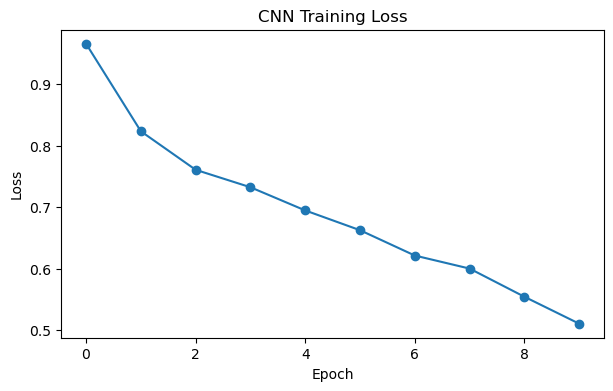

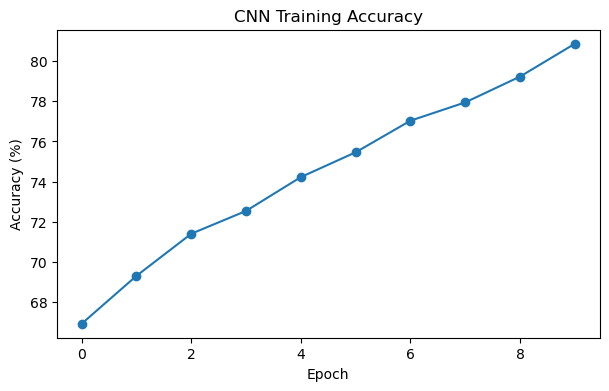

Test Accuracy: 75.19 %
              precision    recall  f1-score   support

       akiec       0.74      0.38      0.51        65
         bcc       0.58      0.50      0.53       103
         bkl       0.48      0.43      0.45       220
          df       0.67      0.09      0.15        23
         mel       0.52      0.32      0.40       223
          nv       0.84      0.93      0.88      1341
        vasc       0.31      0.68      0.43        28

    accuracy                           0.75      2003
   macro avg       0.59      0.47      0.48      2003
weighted avg       0.74      0.75      0.73      2003



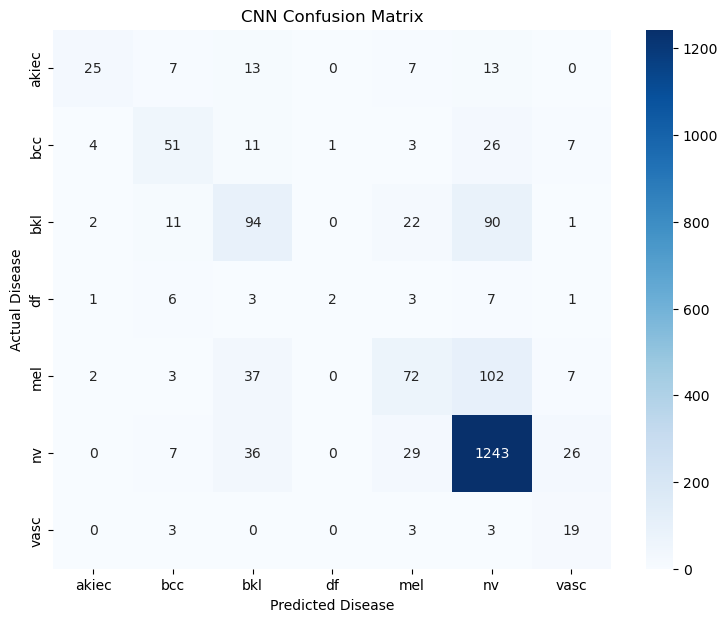

In [1]:
import os
import glob
import zipfile
from sklearn.preprocessing import LabelEncoder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# FIX 1: Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

with zipfile.ZipFile("HAM10000_images_part_1.zip", "r") as zip_ref:
    zip_ref.extractall("HAM10000_images_part_1")

with zipfile.ZipFile("HAM10000_images_part_2.zip", "r") as zip_ref:
    zip_ref.extractall("HAM10000_images_part_2")

print("ZIP files extracted successfully")

df = pd.read_csv("HAM10000_metadata.csv")

print(df.head())
print("Dataset shape:", df.shape)

median_age = df["age"].median()
print("Median age:", median_age)
df["age"] = df["age"].fillna(median_age)
df = df.dropna(subset=["image_id", "dx"]).copy()

print("Total records:", len(df))

images1 = glob.glob(
    "HAM10000_images_part_1/**/*.jpg",
    recursive=True
)

images2 = glob.glob(
    "HAM10000_images_part_2/**/*.jpg",
    recursive=True
)

all_images = images1 + images2

print("Part 1:", len(images1))
print("Part 2:", len(images2))
print("Total:", len(all_images))

image_dict = {}

for path in all_images:
    image_name = os.path.splitext(os.path.basename(path))[0]
    image_dict[image_name] = path

df["image_path"] = df["image_id"].map(image_dict)

print("Matched:", df["image_path"].notna().sum())
print("Missing:", df["image_path"].isna().sum())

df = df.dropna(subset=["image_path"]).copy()
print("Final dataset:", df.shape)

# Create LabelEncoder
le = LabelEncoder()

# Encode disease names
df["label"] = le.fit_transform(df["dx"])

# FIX 2: Define classes for classification_report and confusion_matrix
classes = le.classes_

# Display disease classes
print("Disease classes:")
for index, disease in enumerate(classes):
    print(index, "=", disease)

# Display encoded data
print(df[["dx", "label"]].head())

# Input and output
X = df["image_path"]
y = df["label"]

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

train_df = pd.DataFrame({
    "image_path": X_train,
    "label": y_train
}).reset_index(drop=True)

test_df = pd.DataFrame({
    "image_path": X_test,
    "label": y_test
}).reset_index(drop=True)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

class SkinDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        image_path = self.dataframe.iloc[index]["image_path"]
        label = int(self.dataframe.iloc[index]["label"])

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

train_dataset = SkinDiseaseDataset(
    train_df,
    transform=transform
)

test_dataset = SkinDiseaseDataset(
    test_df,
    transform=transform
)

print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

class SkinCNN(nn.Module):

    def __init__(self, num_classes=7):
        super(SkinCNN, self).__init__()

        self.features = nn.Sequential(
            # First convolution block
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SkinCNN(num_classes=len(classes)).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

loss = criterion(outputs, labels)
print("Initial loss:", loss.item())

epochs = 10

train_losses = []
train_accuracies = []

for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward propagation
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update model weights
        optimizer.step()

        running_loss += loss.item()

        # Calculate predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Calculate epoch loss and accuracy
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

plt.figure(figsize=(7, 4))
plt.plot(train_losses, marker="o")
plt.title("CNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(train_accuracies, marker="o")
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.show()

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.show()

In [ ]:


#IMAGE TRANSFORMATION

import torchvision.models as models

resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

resnet_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


#CREATE RESNET50 DATASETS

resnet_train_dataset = SkinDiseaseDataset(
    train_df,
    transform=resnet_train_transform
)

resnet_test_dataset = SkinDiseaseDataset(
    test_df,
    transform=resnet_test_transform
)


#CREATE DATALOADERS

BATCH_SIZE = 32

resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("ResNet50 DataLoaders Created Successfully")


#LOAD PRETRAINED RESNET50 MODEL

resnet_model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Freeze pretrained layers

for param in resnet_model.parameters():
    param.requires_grad = False

# Replace final classification layer

num_features = resnet_model.fc.in_features

resnet_model.fc = nn.Linear(
    num_features,
    len(classes)
)

resnet_model = resnet_model.to(device)

print(resnet_model)


# 5. LOSS FUNCTION AND OPTIMIZER

criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)


#TRAINING FUNCTION

def train_resnet(model, train_loader, criterion, optimizer, epochs):

    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):

        model.train()

        # Keep frozen BatchNorm layers in evaluation mode
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                if not any(p.requires_grad for p in module.parameters()):
                    module.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            # Forward propagation
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader)

        epoch_accuracy = 100 * correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    return train_losses, train_accuracies


#FIRST PHASE: FEATURE EXTRACTION

print("\nStarting ResNet50 Feature Extraction")

resnet_train_losses, resnet_train_accuracies = train_resnet(
    resnet_model,
    resnet_train_loader,
    criterion_resnet,
    optimizer_resnet,
    epochs=5
)


#SECOND PHASE: FINE-TUNING

# Unfreeze final ResNet50 block

for param in resnet_model.layer4.parameters():
    param.requires_grad = True

# Different learning rates

optimizer_resnet = optim.Adam([
    {
        "params": resnet_model.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": resnet_model.fc.parameters(),
        "lr": 0.0001
    }
])

print("\nStarting ResNet50 Fine-Tuning")

fine_losses, fine_accuracies = train_resnet(
    resnet_model,
    resnet_train_loader,
    criterion_resnet,
    optimizer_resnet,
    epochs=5
)


#COMBINE TRAINING HISTORY

all_resnet_losses = resnet_train_losses + fine_losses

all_resnet_accuracies = (
    resnet_train_accuracies + fine_accuracies
)


#TRAINING LOSS GRAPH

plt.figure(figsize=(8, 5))

plt.plot(
    all_resnet_losses,
    marker="o"
)

plt.title("ResNet50 Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


#TRAINING ACCURACY GRAPH

plt.figure(figsize=(8, 5))

plt.plot(
    all_resnet_accuracies,
    marker="o"
)

plt.title("ResNet50 Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.show()


#MODEL EVALUATION

resnet_model.eval()

y_true_resnet = []
y_pred_resnet = []

with torch.no_grad():

    for images, labels in resnet_test_loader:

        images = images.to(device)

        outputs = resnet_model(images)

        _, predicted = torch.max(outputs, 1)

        y_true_resnet.extend(labels.numpy())

        y_pred_resnet.extend(
            predicted.cpu().numpy()
        )

print("ResNet50 Evaluation Completed")


#PERFORMANCE METRICS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

resnet_accuracy = accuracy_score(
    y_true_resnet,
    y_pred_resnet
)

resnet_precision = precision_score(
    y_true_resnet,
    y_pred_resnet,
    average="macro",
    zero_division=0
)

resnet_recall = recall_score(
    y_true_resnet,
    y_pred_resnet,
    average="macro",
    zero_division=0
)

resnet_f1 = f1_score(
    y_true_resnet,
    y_pred_resnet,
    average="macro",
    zero_division=0
)

print("\nRESNET50 RESULTS")

print("Accuracy:", round(resnet_accuracy * 100, 2), "%")
print("Precision:", round(resnet_precision, 4))
print("Recall:", round(resnet_recall, 4))
print("Macro F1 Score:", round(resnet_f1, 4))


#CLASSIFICATION REPORT

print("\nClassification Report:\n")

print(
    classification_report(
        y_true_resnet,
        y_pred_resnet,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)


#CONFUSION MATRIX

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet,
    labels=list(range(len(classes)))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.show()




#FINAL RESULTS



print("Model: ResNet50")
print("Dataset: HAM10000")
print("Number of Classes:", len(classes))

print(
    "Test Accuracy:",
    round(resnet_accuracy * 100, 2),
    "%"
)

print("Precision:", round(resnet_precision, 4))
print("Recall:", round(resnet_recall, 4))
print("Macro F1:", round(resnet_f1, 4))
print("\nPROJECT COMPLETED SUCCESSFULLY!")
